ECE 3715 Mini Project 1

Team Members: Jovanni Munoz, 

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import binom, poisson, geom
from scipy.stats import norm

from mp1lib import (
    bsc,
    packet_errors,
    attempts_until_clean,
    tv_distance
)

print("Setup complete.")

Setup complete.


In [10]:
# Main random number generator (Team number=5)
SEED = 5
rng = np.random.default_rng(SEED)

# Independent generators with one for each step
rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]

N = 1000000

# Test: BSC and it must return [0, 1, 0, 1] because the p=0
bits = np.array([0, 1, 0, 1])
print(bsc(bits, 0, rng_step1))

# Test: Packet errors
x = packet_errors(10000, 1000, 0, rng_step4)
assert np.all(x == 0)

# Test: Geometric attempts
t = attempts_until_clean(10000, 1, rng_step6)
assert np.all(t == 1)

# Test: Total variation distance
assert tv_distance([0.5, 0.5], [0.5, 0.5]) == 0
assert tv_distance([1, 0], [0, 1]) == 1
print("All function tests passed.")

[0 1 0 1]
All function tests passed.


In [30]:
#Set error probability and create a list
p = 0.1
patterns = []
#Go through all possible bit combinations and change them to binary format
for i in range(16):
    pattern = format(i, "04b")
    patterns.append(pattern)
#Display all bit combinations
print(patterns)
#create a list for the probability of each bit combination
exact_probabilities = []
#Use the formula to calculate probability of each combination
for pattern in patterns:
    k = pattern.count("1")
    probability = (p ** k) * ((1-p) ** (4-k))
    exact_probabilities.append(probability)
#Display the probability of each combination and its sum
print(exact_probabilities)
print("Sum =", sum(exact_probabilities))

['0000', '0001', '0010', '0011', '0100', '0101', '0110', '0111', '1000', '1001', '1010', '1011', '1100', '1101', '1110', '1111']
[0.6561, 0.0729, 0.0729, 0.008100000000000001, 0.0729, 0.008100000000000001, 0.008100000000000001, 0.0009000000000000002, 0.0729, 0.008100000000000001, 0.008100000000000001, 0.0009000000000000002, 0.008100000000000001, 0.0009000000000000002, 0.0009000000000000002, 0.00010000000000000002]
Sum = 1.0


P(A) = 1−(1−p)^2
P(A) = 1-(1-.1)^2
P(A) = 1-.81 = .19

P(A) = .19


P(B) =  \({4 \choose 2}\)*p^2(1-p)^2
P(B) = (6)*.1^2(1-.1)^2
P(B) = (6)*.1^2(.9)^2

P(B) = .0486

P(C) = .1

In [55]:
#Generate 1000000 packets with 4 bits in each one and error probability of .1
N = 1000000
errors = rng_step1.random((N1, 4)) < 0.1
#Check if A, B, and C happen and how many times
A = np.any(errors[:, :2], axis=1)
B = errors.sum(axis=1) == 2
C = errors[:, 3] 
events = [A, B, C]
#Estimate probability that each one happens
for name, event in zip(["A", "B", "C"], events):
    A_estimate = A.mean()
    B_estimate = B.mean()
    C_estimate = C.mean()

print("Estimate A:", A_estimate)
print("Estimate B:", B_estimate)
print("Estimate C:", C_estimate)

Estimate A: 0.190439
Estimate B: 0.048877
Estimate C: 0.100306


In [80]:
#Compute three pairwise intersections and triple intersections empirically
pairs = [
    ("A and B:", A & B),
    ("A and C:", A & C),
    ("B and C:", B & C),
    ("A and B and C:", A & B & C)
]
AB, AC, BC, ABC = [pair[1] for pair in pairs]

AB_estimate = AB.mean()
AC_estimate = AC.mean()
BC_estimate = BC.mean()
ABC_estimate = ABC.mean()

#print probability of each pair
print("Estimate A and B:", AB_estimate)
print("Estimate A and C:", AC_estimate)
print("Estimate B and C:", BC_estimate)
print("Estimate A and B and C:", ABC_estimate)

Estimate A and B: 0.040735
Estimate A and C: 0.018983
Estimate B and C: 0.024265
Estimate A and B and C: 0.016123


In [32]:
#Compute three pairwise intersections and triple intersections exactly using original 16 patterns
patterns = np.array(patterns)
exact_probabilities = np.array(exact_probabilities)
A_exact = np.array([pattern[0] == "1" or pattern[1] == "1" for pattern in patterns])
B_exact = np.array([pattern.count("1") == 2 for pattern in patterns])
C_exact = np.array([pattern[3] == "1" for pattern in patterns])
P_AB = np.sum(exact_probabilities[A_exact & B_exact])
P_AC = np.sum(exact_probabilities[A_exact & C_exact])
P_BC = np.sum(exact_probabilities[B_exact & C_exact])
P_ABC = np.sum(exact_probabilities[A_exact & B_exact & C_exact])

#print probability of each pair exactly
print("Exact P(A and B) =", P_AB)
print("Exact P(A and C) =", P_AC)
print("Exact P(B and C) =", P_BC)
print("Exact P(A and B and C) =", P_ABC)

Exact P(A and B) = 0.04050000000000001
Exact P(A and C) = 0.019000000000000006
Exact P(B and C) = 0.024300000000000002
Exact P(A and B and C) = 0.016200000000000003


Exact P(A∪B∪C)= P(A)+P(B)+P(C)−P(A∩B)−P(A∩C)−P(B∩C)+P(A∩B∩C)

Exact P(A∪B∪C)= .19+.0486+.1-0.04050000000000001-0.04050000000000001-0.024300000000000002+0.016200000000000003

Exact P(A∪B∪C)= .271

In [37]:
#exact probability of A, B, and C
P_A = np.sum(exact_probabilities[A_exact])
P_B = np.sum(exact_probabilities[B_exact])
P_C = np.sum(exact_probabilities[C_exact])

#use exact probability to calculate exact probability of the inclusion-exclusion formula
P_union = P_A + P_B + P_C - P_AB - P_AC - P_BC + P_ABC
print("Exact P(A or B or C) =", P_union)

Exact P(A or B or C) = 0.271


In [54]:
#use empirical probability to calculate empirical probability of the inclusion-exclusion formula
P_estimate = A_estimate + B_estimate + C_estimate - AB_estimate - AC_estimate - BC_estimate + ABC_estimate
print("Empirical P(A or B or C) =", P_estimate)

Empirical P(A or B or C) = 0.27134600000000003


In [78]:
#standard error of probability estimate at N=10^6
N = 10**6
#standard error formula
def standard_error(phat, N):
    return np.sqrt(phat * (1 - phat) / N)
#standard error of probability A estimate
stde_A = standard_error(A_estimate, N)
#display standard error
print("Standard Error:", stde_A)

Standard Error: 0.0003926474083436691


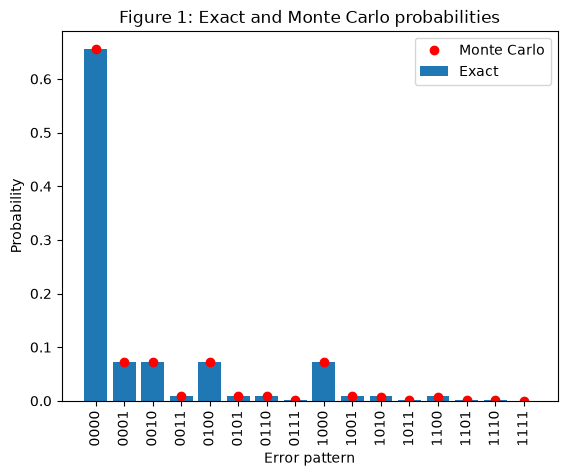

In [81]:
#plot the figure bar chart with x values and label the bar chart Exact
plt.figure()
x = np.arange(16)
plt.bar(x, exact_probabilities, label="Exact")

#Monte Carlo estimates with different patterns and their values 
mc_probability_pattern = np.zeros(16)
"""determines which of the 1 million packets have an exact pattern so that it can use it as an 
estimate for that pattern"""
for i, pattern in enumerate(patterns):
    mc_probability_pattern[i] = np.mean(np.all(errors == np.array([c == "1" for c in pattern]), axis=1))

#plot Monte Carlo estimates
plt.plot(x, mc_probability_pattern, "o", label="Monte Carlo", color="red")

#label the axis and chart
plt.xlabel("Error pattern")
plt.ylabel("Probability")
plt.title("Figure 1: Exact and Monte Carlo probabilities")
plt.xticks(x, patterns, rotation=90)
plt.legend()
plt.show()

In [82]:
import pandas as pd

#Seven exact probabilities
exact = np.array([P_A, P_B, P_C, P_AB, P_AC, P_BC, P_ABC])

#Seven empirical probabilities from Monte Carlo
empirical = np.array([A_estimate, B_estimate, C_estimate, AB_estimate, AC_estimate, BC_estimate, ABC_estimate])

#Difference between empirical and exact
difference = empirical - exact

#Label the values on table
table = pd.DataFrame({"Probability": ["P(A)", "P(B)", "P(C)", "P(A ∩ B)", "P(A ∩ C)", "P(B ∩ C)", "P(A ∩ B ∩ C)"],
                      "Exact": exact,
                      "Empirical": empirical,
                      "Difference": difference})

#Display the table
print(table.to_string(index=False))

 Probability  Exact  Empirical  Difference
        P(A) 0.1900   0.190439    0.000439
        P(B) 0.0486   0.048877    0.000277
        P(C) 0.1000   0.100306    0.000306
    P(A ∩ B) 0.0405   0.040735    0.000235
    P(A ∩ C) 0.0190   0.018983   -0.000017
    P(B ∩ C) 0.0243   0.024265   -0.000035
P(A ∩ B ∩ C) 0.0162   0.016123   -0.000077
